In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

df = pd.read_parquet("../out/ksa_sales_clean.parquet")

# SCOPE — a modelling choice, not a cleaning one. Stated so it can be changed.
m = df[
    (df.classification == "سكني")          # residential only
    & (~df.is_multi_property)              # one property per deal
    & (df.area_m2.between(50, 5_000))      # plausible dwelling size
    & (df.price_sar.between(50_000, 20_000_000))
].copy()

print(f"{len(df):,} cleaned  ->  {len(m):,} in scope  ({len(m)/len(df):.1%})")

1,222,288 cleaned  ->  927,761 in scope  (75.9%)


year
2020     450.0
2021     667.0
2022     879.0
2023    1027.0
2024    1280.0
2025    1298.0
2026    1255.0
dtype: float64


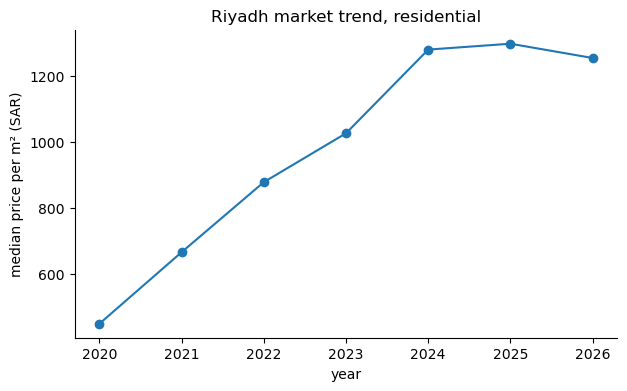

In [2]:
m["year"] = m.date_greg.dt.year
ppm = (m.price_sar / m.area_m2).groupby(m.year).median()
print(ppm.round(0))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ppm.index, ppm.values, marker="o")
ax.set_xlabel("year"); ax.set_ylabel("median price per m² (SAR)")
ax.set_title("Riyadh market trend, residential")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)

In [3]:
# target distribution, raw and logged
print("price skew:", round(m.price_sar.skew(), 2),
      "| log1p:", round(np.log1p(m.price_sar).skew(), 2))

# the reporting floor and round-number clustering
m.price_sar.value_counts().head(10)

# how much data per year — is it balanced?
m.groupby("year").size()

price skew: 6.91 | log1p: 0.06


year
2020    152899
2021    133549
2022    157413
2023    130965
2024    198848
2025    128504
2026     25583
dtype: int64